# Figure 1a
Cell population dynamics -/+ erlotinib on different stiffnesses

#### Load libraries
Should use ECM_model conda environment (see README)

In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
import pandas as pd
import seaborn as sns
import math
from pathlib import Path
import re

from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit

#### Set global parameters
`SAVEFILES` = logical whether to write files to disk  
`OVERWRITE` = logical whether to overwrite files if already exists  
`SAVEDIR` = Path (outside of git repo) to save output files  
`DATADIR` = Path to data files  


In [2]:
SAVEFILES = True
OVERWRITE = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)
    
DATADIR = "../../Data/Exp_Cell_Counts"

rcParams.update({'figure.autolayout': True})

In [3]:
filepaths = os.listdir(DATADIR)
filenames = [f for f in filepaths if re.match(r'^DIP_DS8', f)]
filepaths = [Path(DATADIR, f) for f in filenames]
filepaths.sort()
filepaths

[PosixPath('../../Data/Exp_Cell_Counts/DIP_DS8_0p2kPa_DMSO.txt'),
 PosixPath('../../Data/Exp_Cell_Counts/DIP_DS8_0p2kPa_ERL.txt'),
 PosixPath('../../Data/Exp_Cell_Counts/DIP_DS8_4kPa_DMSO.txt'),
 PosixPath('../../Data/Exp_Cell_Counts/DIP_DS8_4kPa_ERL.txt'),
 PosixPath('../../Data/Exp_Cell_Counts/DIP_DS8_55kPa_DMSO.txt'),
 PosixPath('../../Data/Exp_Cell_Counts/DIP_DS8_55kPa_ERL.txt')]

In [4]:
all_response = []
for f in filepaths:
    all_response.append(np.loadtxt(f,delimiter=','))

means=[]
for vals in range(len(all_response)):
    means.append(np.mean(all_response[vals],axis=1))
    
stdevs=[]
for vals in range(len(all_response)):
    stdevs.append(np.std(all_response[vals],axis=1))
  
t = np.arange(0,420/3,1/3)
t1 = np.arange(0,363/3,1/3)


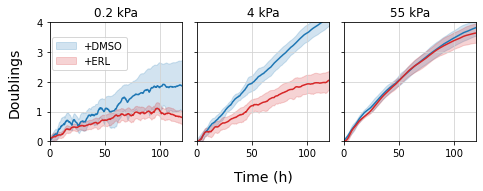

In [5]:
win = 21
pol = 2
size = (7,3)
c1 = "tab:blue"
c2 = "tab:red"
xmin = 0
xmax = 120
ymin = 0
ymax = 4

fig, axes = plt.subplots(1, 3, figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

axes[0].plot(t, savgol_filter(means[0],win,pol), color=c1)
axes[0].fill_between(t, savgol_filter(means[0] - stdevs[0],win,pol),
                     savgol_filter(means[0] + stdevs[0],win,pol), color=c1, alpha=0.2, label='+DMSO')
axes[0].plot(t, savgol_filter(means[1],win,pol), color=c2)
axes[0].fill_between(t, savgol_filter(means[1] - stdevs[1],win,pol),
                     savgol_filter(means[1] + stdevs[1],win,pol), color=c2, alpha=0.2, label='+ERL')
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('0.2 kPa')
axes[0].grid(color='lightgray')
axes[0].legend(loc=(0.02,0.6))

axes[1].plot(t, savgol_filter(means[2],win,pol), color=c1)
axes[1].fill_between(t, savgol_filter(means[2] - stdevs[2],win,pol), 
                     savgol_filter(means[2] + stdevs[2],win,pol), color=c1, alpha=0.2)
axes[1].plot(t, savgol_filter(means[3],win,pol), color=c2)
axes[1].fill_between(t, savgol_filter(means[3] - stdevs[3],win,pol), 
                     savgol_filter(means[3] + stdevs[3],win,pol), color=c2, alpha=0.2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
axes[1].title.set_text('4 kPa')
axes[1].grid(color='lightgray')

axes[2].plot(t1, savgol_filter(means[4],win,pol), color=c1)
axes[2].fill_between(t1, savgol_filter(means[4] - stdevs[4],win,pol), 
                     savgol_filter(means[4] + stdevs[4],win,pol), color=c1, alpha=0.2)
axes[2].plot(t1, savgol_filter(means[5],win,pol), color=c2)
axes[2].fill_between(t1, savgol_filter(means[5] - stdevs[5],win,pol), 
                     savgol_filter(means[5] + stdevs[5],win,pol), color=c2, alpha=0.2)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])
axes[2].title.set_text('55 kPa')
axes[2].grid(color='lightgray')


    
ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('Time (h)', labelpad=25)
ax.set_ylabel('Doublings', labelpad=25)
fig.tight_layout(rect=(0, 0, 1, 1))

fig1a_fn = Path(SAVEDIR, 'fig1a.svg')

if SAVEFILES and (OVERWRITE or not fig1a_fn.exists()):
    plt.savefig(fig1a_fn, bbox_inches='tight')
else:
    plt.figure()

# Fig 1b
Distributions of intermitotic times (IMT) of cells treated with erlotinib (red shading) or DMSO control (blue shading) on three different substrate stiffnesses.

In [6]:
IMT_DATADIR = Path("../../Data/Exp_Intermitotic_Times")

In [7]:
file_location = os.path.join(IMT_DATADIR,'*imt*.csv')
filenames = glob.glob(file_location)
filenames.sort()
filenames


['../../Data/Exp_Intermitotic_Times/02kpa_dmso_imt_190118.csv',
 '../../Data/Exp_Intermitotic_Times/02kpa_erl_imt_190118.csv',
 '../../Data/Exp_Intermitotic_Times/06kpa_dmso_imt_181017.csv',
 '../../Data/Exp_Intermitotic_Times/06kpa_erl_imt_181017.csv',
 '../../Data/Exp_Intermitotic_Times/4kpa_dmso_imt_190118.csv',
 '../../Data/Exp_Intermitotic_Times/4kpa_erl_imt_190118.csv',
 '../../Data/Exp_Intermitotic_Times/55kpa_dmso_imt_181017.csv',
 '../../Data/Exp_Intermitotic_Times/55kpa_erl_imt_181017.csv']

In [8]:
IMTs = []
for f in filenames:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

ii=0
for df in IMTs:
    df["IMT"] = df["Division"] - df["Mitotic Frame"]
    df["G1"] = df["Green On"] - df["Mitotic Frame"]
    df["S-M"] = df["Division"] - df["Green On"]
    if ii == 2 or ii == 3 or ii == 6 or ii == 7:
        df["IMT_t"] = df["IMT"] * (32/60)
        df["G1_t"] = df["G1"] * (32/60)
        df["S-M_t"] = df["S-M"] * (32/60)
    else:
        df["IMT_t"] = df["IMT"] * (20/60)
        df["G1_t"] = df["G1"] * (20/60)
        df["S-M_t"] = df["S-M"] * (20/60)
    #df = df[(df["IMT_t"] ==27)].reset_index(drop=True)
    ii+=1
    
stiffs = [0.2, 0.2, 0.6, 0.6, 4, 4, 55, 55]
ii=0
for df in IMTs:
    tmp_stiff = np.ones(len(df))*stiffs[ii]
    df.insert(0, "Stiffness", tmp_stiff)
    if ii % 2 == 0:
        df["Drug"] = "DMSO"
    else:
        df["Drug"] = "ERL"    
    ii+=1

all_IMTs = pd.concat(IMTs, ignore_index=True, sort=False)
centers = np.arange(0.5, 100.5, 1)

### Define exponentially modified Gaussian (EMG) function

In [9]:
def emg_fit_func(x, l, s, m):
    return 0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s)) # exponentially modified gaussian

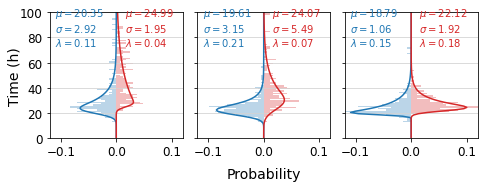

In [10]:
win = 21
pol = 2
size = (7.25,3)
c1 = "tab:blue"
c2 = "tab:red"
xmin = -0.12
xmax = 0.12
ymin = 0
ymax = 100

fig, axes = plt.subplots(1, 3, figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)


h, edges =np.histogram(IMTs[0]["IMT_t"], bins=range(0,101), density=True)
out = axes[0].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[0].plot(fitted_curve, centers, color=c1)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)


h, edges =np.histogram(IMTs[1]["IMT_t"], bins=range(0,101), density=True)
out = axes[0].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0].plot(fitted_curve, centers, color=c2)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)


h, edges =np.histogram(IMTs[4]["IMT_t"], bins=range(0,101), density=True)
out = axes[1].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[1].plot(fitted_curve, centers, color=c1)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)

h, edges =np.histogram(IMTs[5]["IMT_t"], bins=range(0,101), density=True)
out = axes[1].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1].plot(fitted_curve, centers, color=c2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)


h, edges =np.histogram(IMTs[6]["IMT_t"], bins=range(0,101), density=True)
out = axes[2].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[2].plot(fitted_curve, centers, color=c1)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)


h, edges =np.histogram(IMTs[7]["IMT_t"], bins=range(0,101), density=True)
out = axes[2].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[2].plot(fitted_curve, centers, color=c2)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)



ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Probability', labelpad=25)
ax.set_ylabel('Time (h)', labelpad=25)
#fig.tight_layout(rect=(0, 0, 1, 1))

fig1b_fn = Path(SAVEDIR, 'fig1b.svg')

if SAVEFILES and (OVERWRITE or not fig1b_fn.exists()):
    plt.savefig(fig1b_fn, bbox_inches='tight')
else:
    plt.figure()

# Fig 1c
IMT fits with EMG or convolution of two EMGs  
erlotinib-treated only for 3 ECM stiffnesses  


In [11]:
from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit
from scipy import stats
#from pomegranate import *
from sklearn.metrics import mean_squared_error
from sklearn.mixture import GaussianMixture
from scipy.stats import norm
from scipy.special import rel_entr
from sklearn.neighbors import KernelDensity

### Define functions to calculate model fit comparison metrics
Bayesian information criterion (bic)and Aikaike's information criterion (aic)

In [12]:
def calculate_aic(LL, num_params):
    aic = 2*num_params - 2*LL
    return aic

def calculate_bic(LL, num_params, samp_size):
    bic = num_params*math.log(samp_size) - 2*LL
    return bic



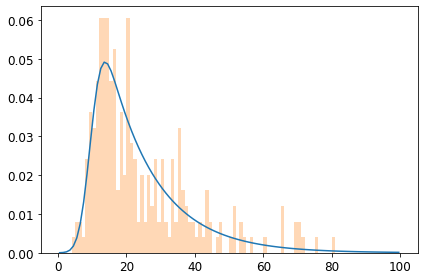

In [13]:
G1_times = np.array(IMTs[5]["G1_t"])
G1_times = G1_times[~np.isnan(G1_times)]
params = exponnorm.fit(G1_times)
exp_c = 1/(params[0]*params[2])
LLH = exponnorm.logpdf(G1_times,*params).sum()
emg_aic = calculate_aic(LLH, 3)
fitted_curve=list(emg_fit_func(centers,exp_c,params[0],params[1]))
plt.plot(centers, fitted_curve)
h, edges =np.histogram(G1_times, bins=range(0,101), density=True)
out = plt.stairs(h, edges, fill=True, alpha=0.3)

In [14]:
all_IMTs

,Stiffness,Mitotic Frame,Green On,Division,IMT,G1,S-M,IMT_t,G1_t,S-M_t,Drug
0,0.2,NaN,11.0,79.0,NaN,NaN,68.0,NaN,NaN,22.666667,DMSO
1,0.2,79.0,140.0,NaN,NaN,61.0,NaN,NaN,20.333333,NaN,DMSO
2,0.2,79.0,149.0,NaN,NaN,70.0,NaN,NaN,23.333333,NaN,DMSO
3,0.2,NaN,70.0,112.0,NaN,NaN,42.0,NaN,NaN,14.000000,DMSO
4,0.2,112.0,143.0,189.0,77.0,31.0,46.0,25.666667,10.333333,15.333333,DMSO
...,...,...,...,...,...,...,...,...,...,...,...
1567,55.0,45.0,83.0,106.0,61.0,38.0,23.0,32.533333,20.266667,12.266667,ERL
1568,55.0,70.0,101.0,133.0,63.0,31.0,32.0,33.600000,16.533333,17.066667,ERL
1569,55.0,71.0,102.0,132.0,61.0,31.0,30.0,32.533333,16.533333,16.000000,ERL
1570,55.0,16.0,40.0,68.0,52.0,24.0,28.0,27.733333,12.800000,14.933333,ERL
